# Simulations of the Heisenberg model alone

* Calculations with only the Heisenberg energy contributions are much faster (~x50 speedup for $L_1=L_2=24$).
* Linear sizes of the cluster must be multiples of 3 to be compatible with the $120^\circ$ Néel order.
* Starting a simulation from a $120^\circ$ Néel state (with $\chi=\pm1$) results in small thermal fluctuations around this state throughout the simulation.
* It is possible to arrive at the $120^\circ$ Néel state starting from a randomized state after a sufficiently high number of steps.
* The version of `UpdateTriangle` that selects angles of all 3 spins independenty has a very low acceptance rate ($5\cdot 10^{-4}$ for $T/J=0.01$) and is basically useless.
* Specific heat can be directly measured as $c_V = \frac{d\langle E\rangle}{dT} = \frac{1}{kT^2} \left[\langle E^2\rangle - \langle E\rangle^2\right]$.
* Idea: Try to suppress domain walls and to speed up convergence towards the $120^\circ$ Néel state by using reweighting with $w(\phi) = e^{\alpha \sum_i(1 - \chi_i^2)}$.
* **TODO:** Use the `@threads` macro to parallelize various loops over nodes.

In [ ]:
using Pkg; Pkg.update()

using MX2RKKY.montecarlo
using MX2RKKY.lattice
using MX2RKKY.visualization: plot_conf

using Random: MersenneTwister
using Statistics: mean, std

using PyPlot; const plt = PyPlot;

In [2]:
# Cluster size
L1, L2 = 24, 24

# Heisenberg parameters
Jpar = 1.0
Jperp = 0.0
# RKKY parameters
Vpar = 0.0
Vperp = 0.0
λ = 0.1 # k_F a_0

0.1

## Energy and chirality evolution at low temperature

120° Néel state as initial state ($\chi=-1$)

In [3]:
T = 0.01

n_cycles = 200000
n_warmup_cycles = 0
cycle_length = 50

conf = Configuration(L1, L2, -1)
sim = MCSimulation(conf, MersenneTwister(123456), β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true, update_triangle_prob=0.1)
acceptance_rates(sim)

Running MC simulation 100%|██████████████████████████████| Time: 0:03:40:30


Dict{DataType, Float64} with 2 entries:
  UpdateTriangle         => 0.0209226
  UpdateSingleSpin{true} => 0.0294253

min_energy(sim) / (L1 * L2) = -1.4999971815283606
avg_energy(sim) / (L1 * L2) = -1.4950589618958032
var_energy(sim) / (L1 * L2) = 0.00034046686775987046
avg_chirality(sim) = -1.0
var_chirality(sim) = 0.0
specific_heat(sim) / (L1 * L2) = 0.6676825432805344


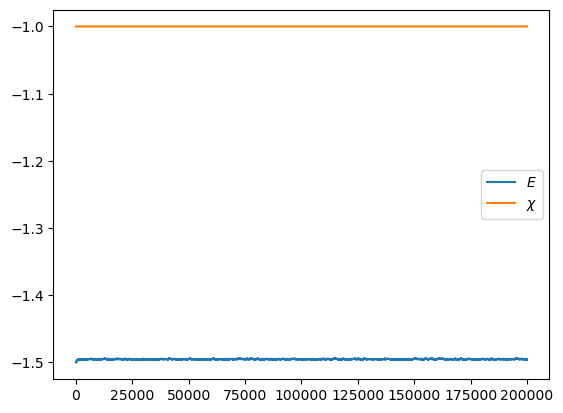

0.6676825432805344

In [4]:
plt.plot(sim.measurements.energy ./ (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.legend()

@show min_energy(sim) / (L1 * L2)
@show avg_energy(sim) / (L1 * L2)
@show var_energy(sim) / (L1 * L2)
@show avg_chirality(sim)
@show var_chirality(sim)
@show specific_heat(sim) / (L1 * L2)

120° Néel state as initial state ($\chi=1$)

In [5]:
T = 0.01

n_cycles = 200000
n_warmup_cycles = 0
cycle_length = 50

conf = Configuration(L1, L2, 1)
sim = MCSimulation(conf, MersenneTwister(123456), β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true, update_triangle_prob=0.1)
acceptance_rates(sim)

Running MC simulation 100%|██████████████████████████████| Time: 0:03:45


Dict{DataType, Float64} with 2 entries:
  UpdateTriangle         => 0.0207875
  UpdateSingleSpin{true} => 0.0293197

min_energy(sim) / (L1 * L2) = -1.5
avg_energy(sim) / (L1 * L2) = -1.4950249016401709
var_energy(sim) / (L1 * L2) = 0.00035943107240071586
1.0_chirality(sim) = 
var_chirality(sim) = 0.0
specific_heat(sim) / (L1 * L2) = 0.7441346861014608


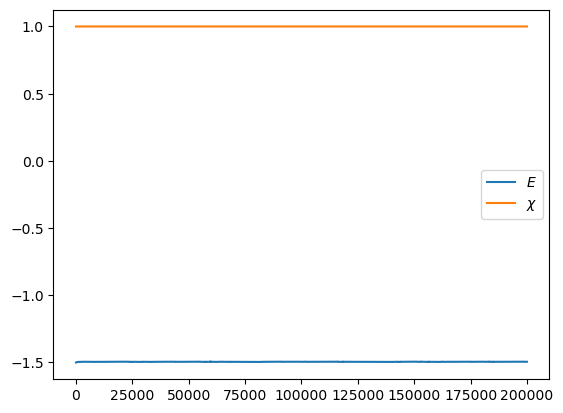

0.7441346861014608

In [6]:
plt.plot(sim.measurements.energy ./ (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.legend()

@show min_energy(sim) / (L1 * L2)
@show avg_energy(sim) / (L1 * L2)
@show var_energy(sim) / (L1 * L2)
@show avg_chirality(sim)
@show var_chirality(sim)
@show specific_heat(sim) / (L1 * L2)

Random initial state

In [15]:
T = 0.01

n_cycles = 200000
n_warmup_cycles = 0
cycle_length = 50

rng = MersenneTwister(123456)
conf = Configuration(L1, L2, rng, inplane=true)
sim = MCSimulation(conf, rng, β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true, update_triangle_prob=0.1)
acceptance_rates(sim)

Running MC simulation 100%|██████████████████████████████| Time: 0:04:04


Dict{DataType, Float64} with 2 entries:
  UpdateTriangle         => 0.021834
  UpdateSingleSpin{true} => 0.0312926

sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


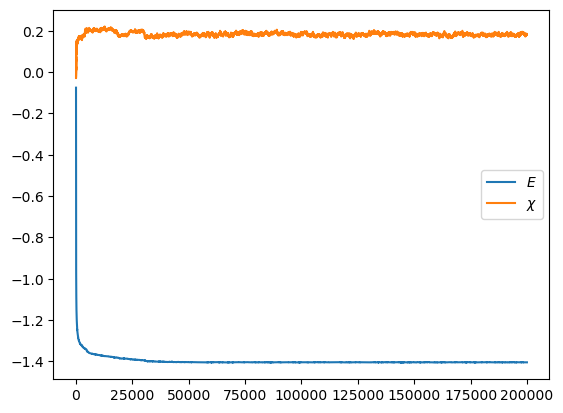

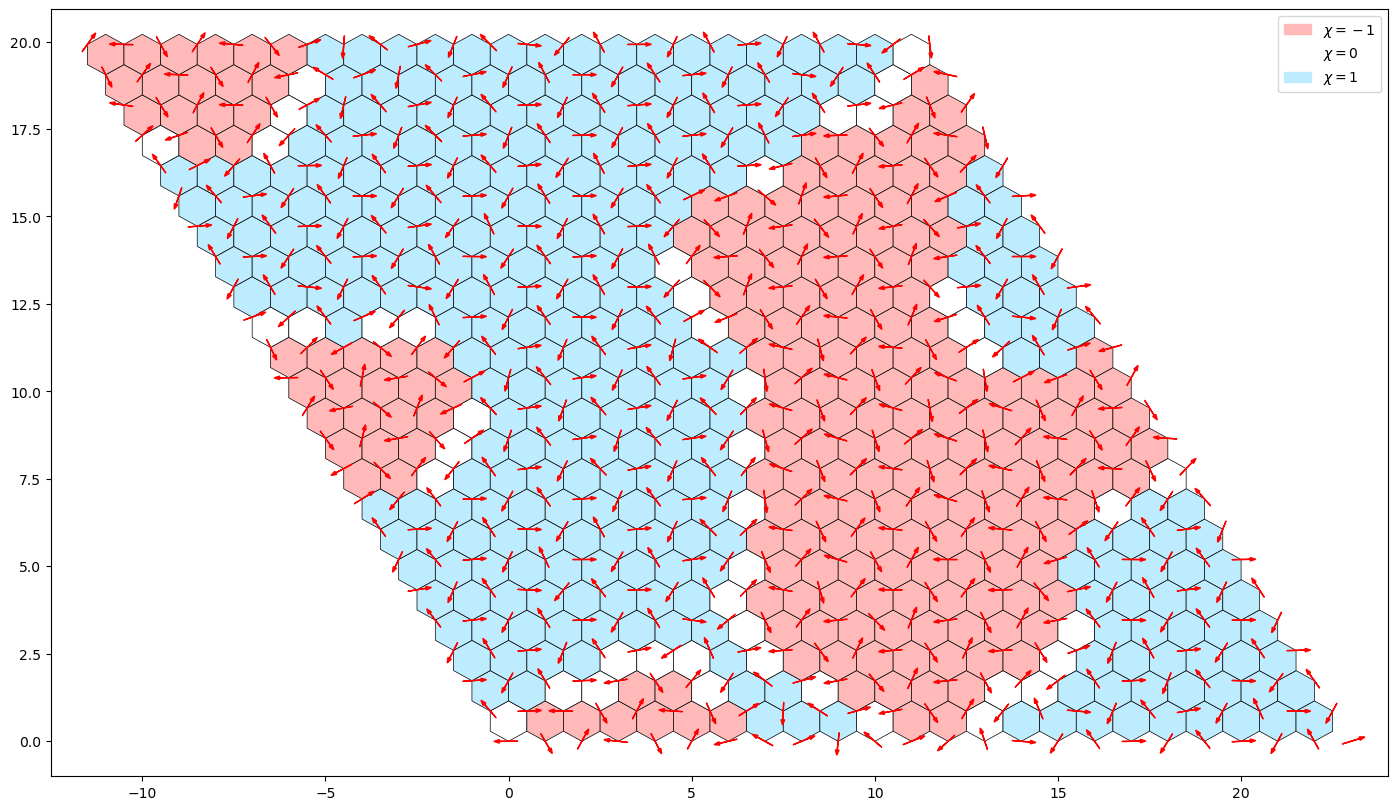

In [16]:
plt.plot(sim.measurements.energy ./ (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.legend()

fig = plot_conf(sim.conf);
fig.savefig("heisenberg_conf_T0.01.pdf")

In [17]:
@show min_energy(sim)
@show avg_energy(sim, 100000:200000) / (L1 * L2)
@show var_energy(sim, 100000:200000) / (L1 * L2)
@show avg_chirality(sim, 100000:200000)
@show var_chirality(sim, 100000:200000)
@show specific_heat(sim, 100000:200000) / (L1 * L2)

min_energy(sim) = -809.4026320423391
avg_energy(sim, 100000:200000) / (L1 * L2) = -1.4042497040241337
var_energy(sim, 100000:200000) / (L1 * L2) = 0.0002983527325901911
avg_chirality(sim, 100000:200000) = 0.18144129322595665
var_chirality(sim, 100000:200000) = 0.006094630052492468
specific_heat(sim, 100000:200000) / (L1 * L2) = 0.5127175447543979


0.5127175447543979

Random initial state, higher temperature

In [18]:
T = 0.1

n_cycles = 250000
n_warmup_cycles = 0
cycle_length = 50

# seed = 127459: Fully polarized solution after ~200000 cycles
rng = MersenneTwister(127459)
conf = Configuration(L1, L2, rng, inplane=true)
sim = MCSimulation(conf, rng, β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true, update_triangle_prob=0.1)
acceptance_rates(sim)

Running MC simulation 100%|██████████████████████████████| Time: 0:05:16


Dict{DataType, Float64} with 2 entries:
  UpdateTriangle         => 0.0678617
  UpdateSingleSpin{true} => 0.0967548

sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


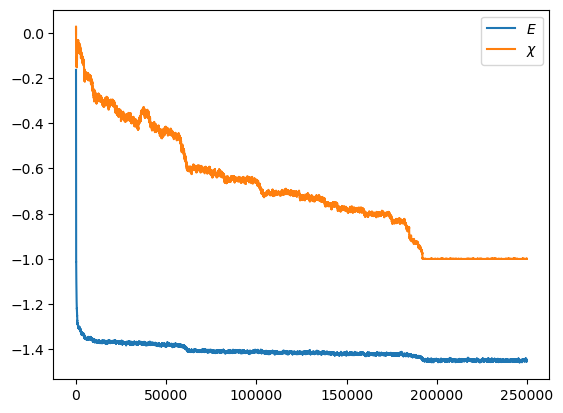

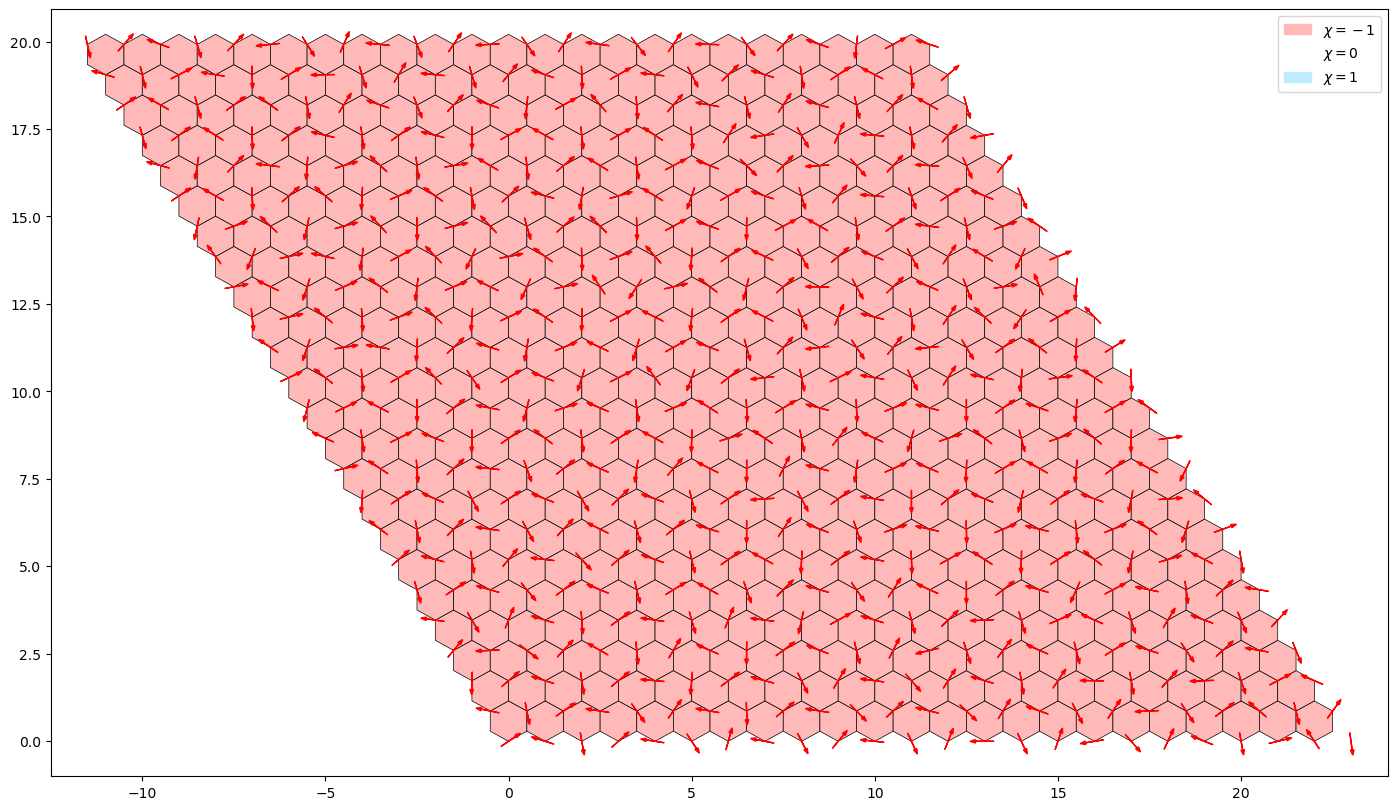

In [19]:
plt.plot(sim.measurements.energy ./ (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.legend()

fig = plot_conf(sim.conf);
fig.savefig("heisenberg_conf_T0.1.pdf")

In [20]:
@show min_energy(sim) / (L1 * L2)
@show avg_energy(sim, 200000:250000) / (L1 * L2)
@show var_energy(sim, 200000:250000) / (L1 * L2)
@show avg_chirality(sim, 200000:250000)
@show var_chirality(sim, 200000:250000)
@show specific_heat(sim, 100000:200000) / (L1 * L2)

min_energy(sim) / (L1 * L2) = -1.457663030162404
avg_energy(sim, 200000:250000) / (L1 * L2) = -1.4486232533116778
var_energy(sim, 200000:250000) / (L1 * L2) = 0.0029619288936492943
avg_chirality(sim, 200000:250000) = -0.9999307305520555
var_chirality(sim, 200000:250000) = 0.00034612683920791696
specific_heat(sim, 100000:200000) / (L1 * L2) = 5.574868331981027


5.574868331981027

New triangle update

Running MC simulation 100%|██████████████████████████████| Time: 0:47:49


acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.montecarlo.UpdateTriangle => 0.000540545951410925, MX2RKKY.montecarlo.UpdateSingleSpin{true} => 0.034806093982786376)
avg_chirality(sim) = 0.09708020833333013
var_chirality(sim) = 0.03839290143001038


sys:1: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


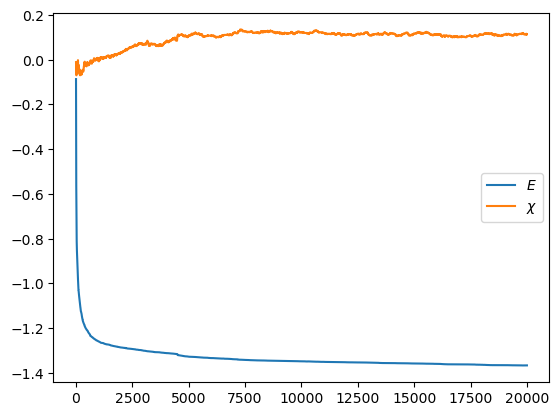

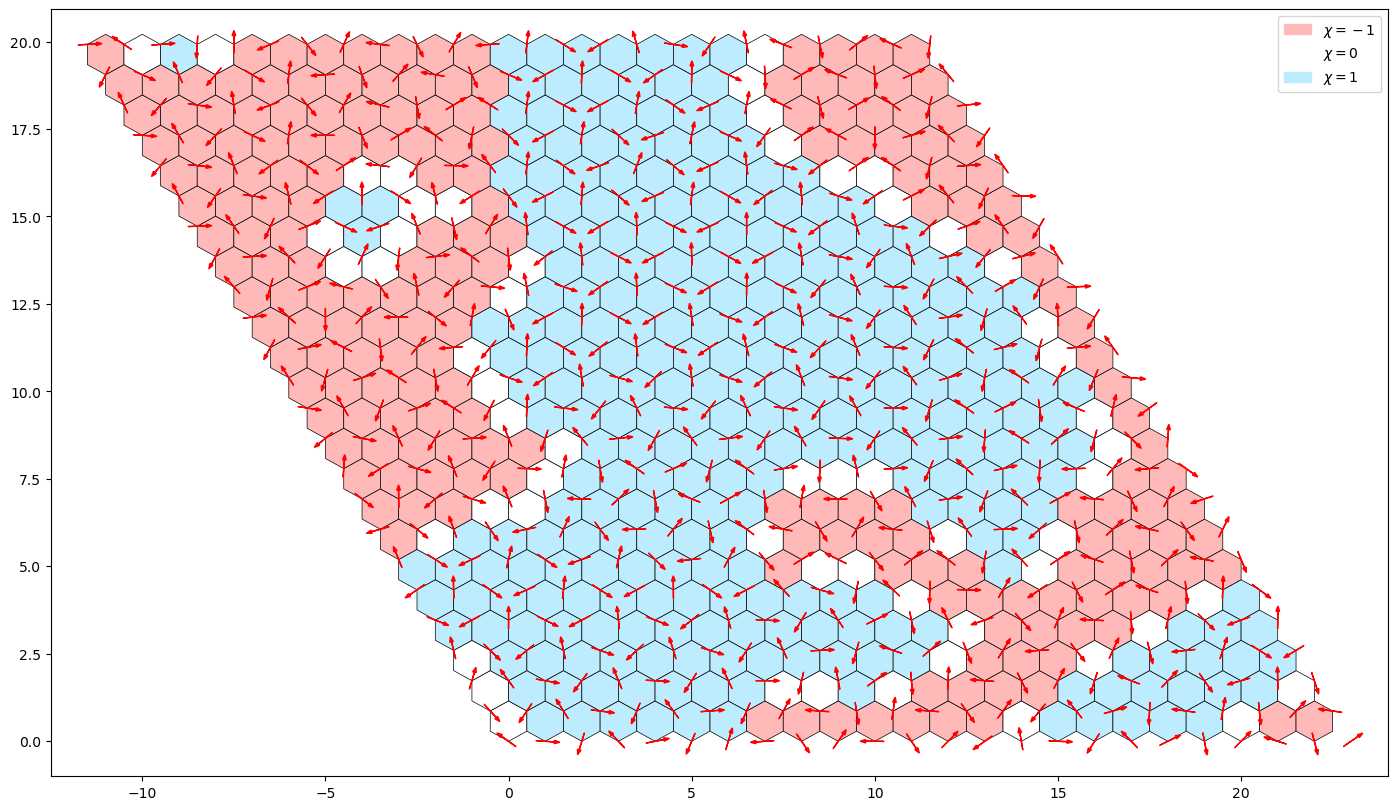

In [3]:
T = 0.01

n_cycles = 20000
n_warmup_cycles = 0
cycle_length = 50

rng = MersenneTwister(123456)
conf = Configuration(L1, L2, rng, inplane=true)
sim = MCSimulation(conf, β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true, update_triangle_prob=0.1)

@show acceptance_rates(sim)
@show avg_chirality(sim)
@show var_chirality(sim)

plt.plot(sim.measurements.energy ./ (L1 * L2), label=raw"$E$")
plt.plot(sim.measurements.chirality, label=raw"$\chi$")
plt.legend()

fig = plot_conf(sim.conf);
fig.savefig("conf_new_update.pdf")

## Temperature scan

In [72]:
# Cluster size
L1, L2 = 24, 24

# Heisenberg parameters
Jpar = 1.0
Jperp = 0.0
# RKKY parameters
Vpar = 0.0
Vperp = 0.0
λ = 0.1

# Temperature range
T_range = 0.05:0.05:3.0

n_cycles = 200000
n_warmup_cycles = 0
cycle_length = 50

E = zeros(n_cycles, length(T_range))
χ = zeros(n_cycles, length(T_range))

rng = MersenneTwister(123456)
conf = Configuration(L1, L2, -1)

for (n, T) in enumerate(T_range)
    @show T
    sim = MCSimulation(conf, rng, β=1/T, Jpar=Jpar, Jperp=Jperp, Vpar=Vpar, Vperp=Vperp, λ=λ, Vrenormalize=false)
    run!(sim, n_cycles=n_cycles, n_warmup_cycles=n_warmup_cycles, cycle_length=cycle_length, inplane=true, update_triangle_prob=0.1)
    @show acceptance_rates(sim)

    E[:, n] = sim.measurements.energy
    χ[:, n] = sim.measurements.chirality

    conf = deepcopy(sim.conf)
end

write("heisenberg_T_scan_E.dat", E)
write("heisenberg_T_scan_chi.dat", χ)

T = 0.05


Running MC simulation 100%|██████████████████████████████| Time: 0:03:23


acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.montecarlo.UpdateTriangle => 0.0469309743229406, MX2RKKY.montecarlo.UpdateSingleSpin{true} => 0.06629865312911311)
T = 0.1


Running MC simulation 100%|██████████████████████████████| Time: 0:03:29


acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.montecarlo.UpdateTriangle => 0.0664820249376359, MX2RKKY.montecarlo.UpdateSingleSpin{true} => 0.09485906242798792)
T = 0.15


Running MC simulation 100%|██████████████████████████████| Time: 0:03:31


... (112 outputs left out)

acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.montecarlo.UpdateTriangle => 0.6551115775795286, MX2RKKY.montecarlo.UpdateSingleSpin{true} => 0.7493040504690499)
T = 3.0


Running MC simulation 100%|██████████████████████████████| Time: 0:04:06


acceptance_rates(sim) = Dict{DataType, Float64}(MX2RKKY.montecarlo.UpdateTriangle => 0.6586110663929582, MX2RKKY.montecarlo.UpdateSingleSpin{true} => 0.7523798296182772)


96000000

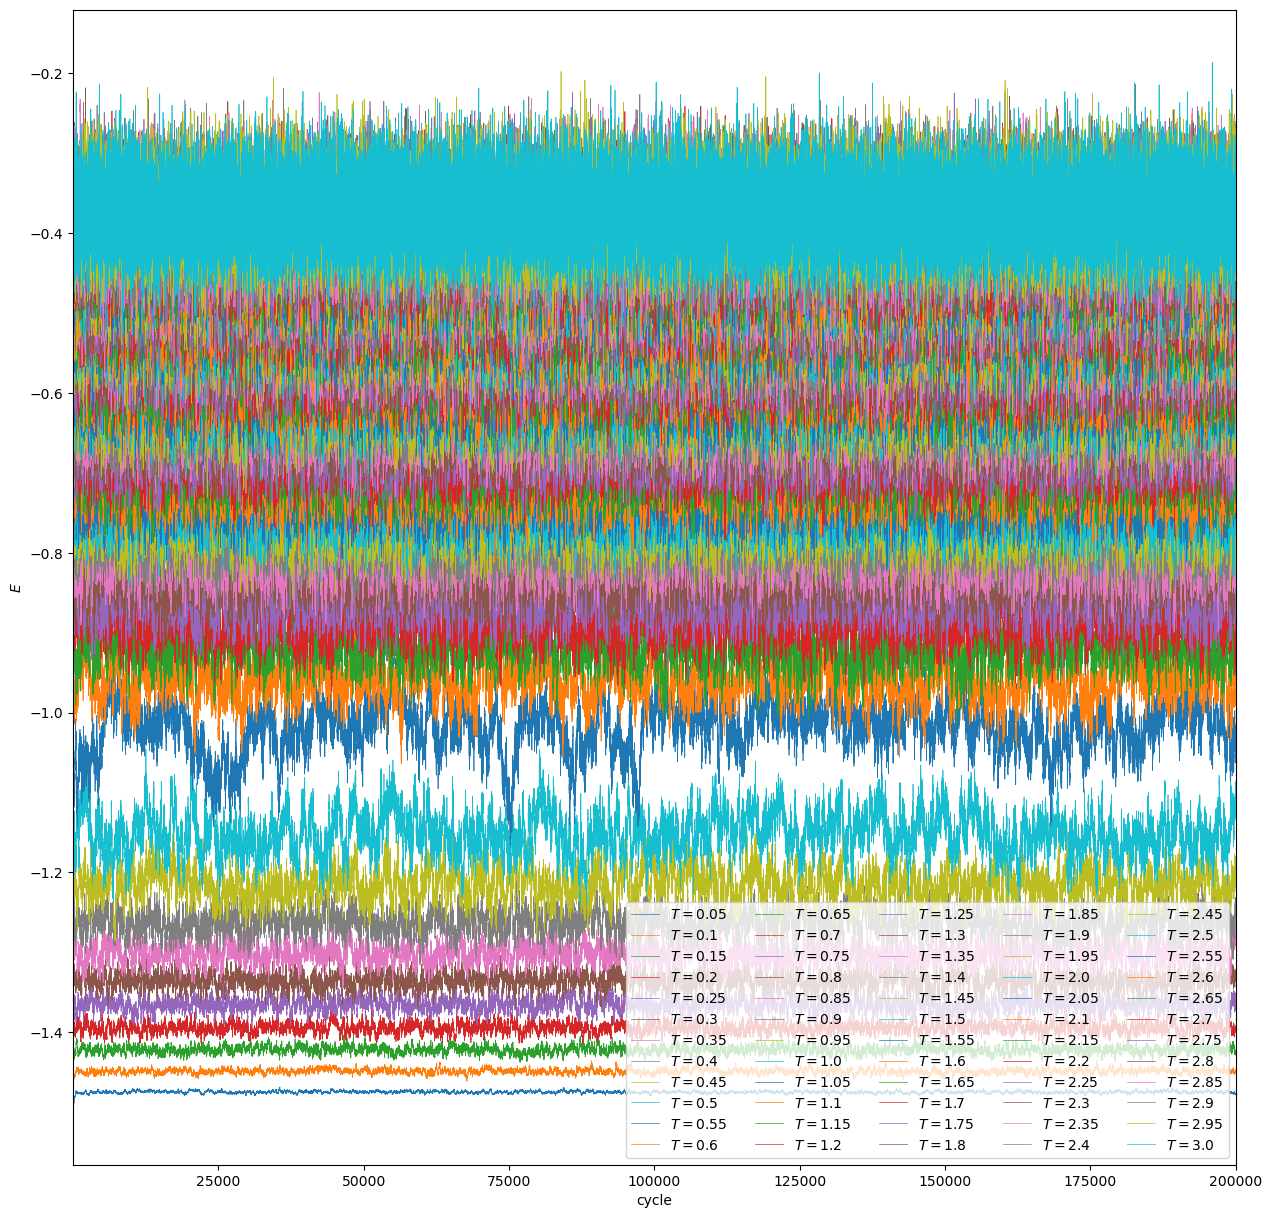

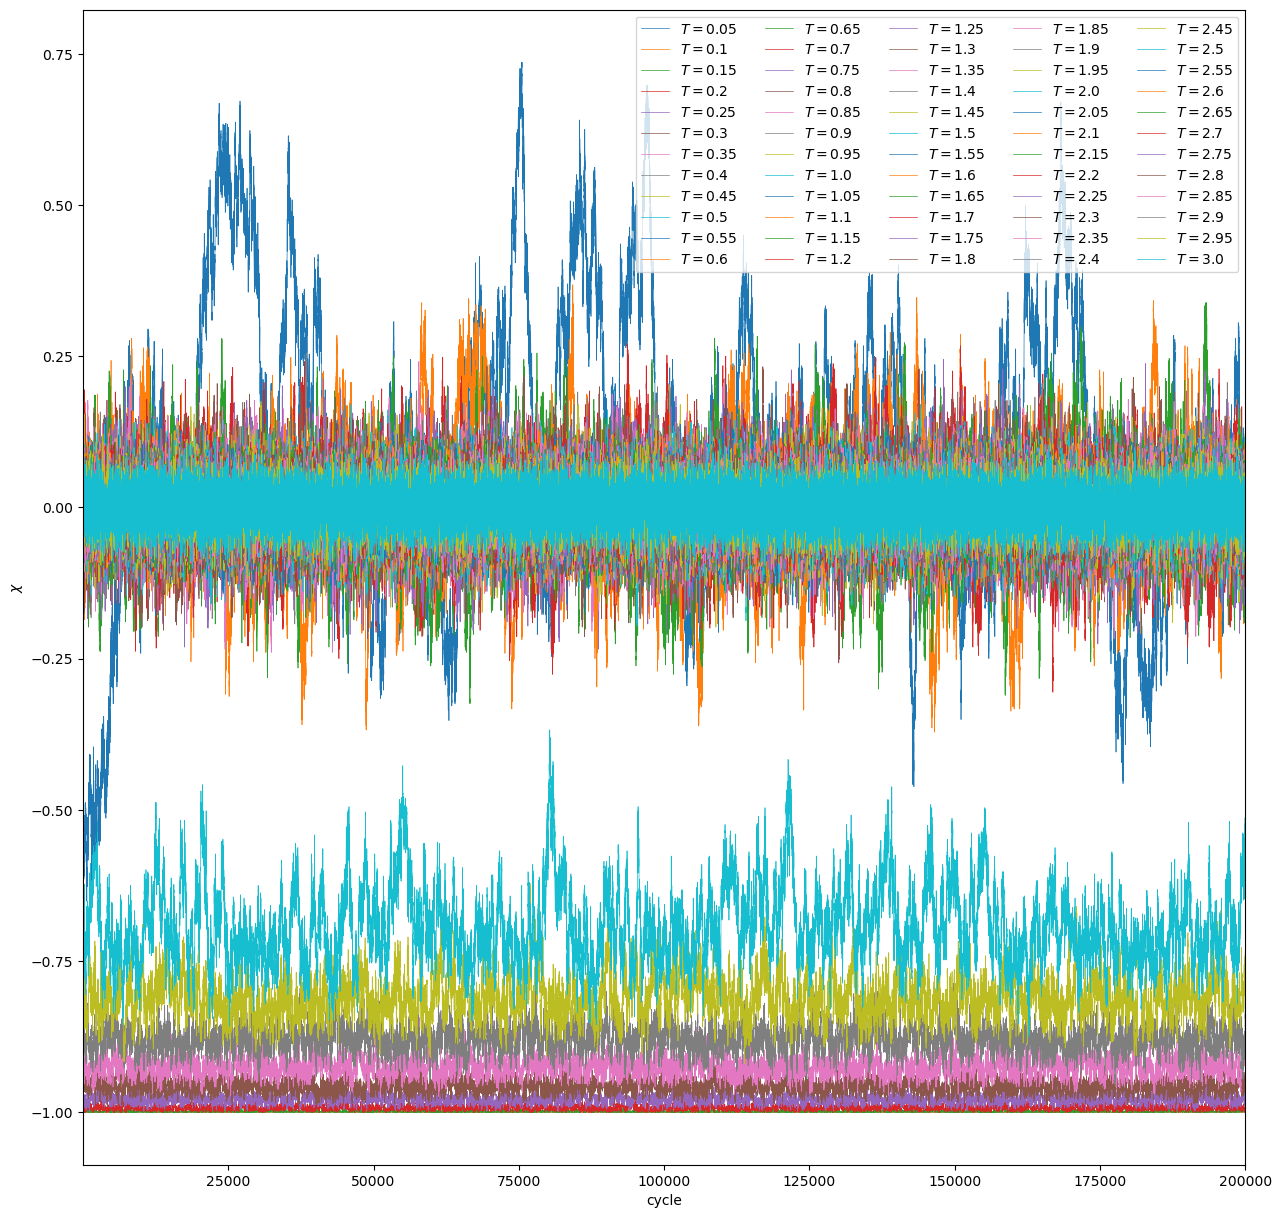

In [73]:
plt.figure(figsize=(15, 15))
for (n, T) in enumerate(T_range)
    plt.plot(E[:, n] / (L1 * L2), label="\$T=$(T)\$", lw=0.5)
end
plt.xlim((1, n_cycles))
plt.xlabel("cycle")
plt.ylabel(raw"$E$")
plt.legend(loc="best", ncol=5)
plt.show()

plt.figure(figsize=(15, 15))
for (n, T) in enumerate(T_range)
    plt.plot(χ[:, n], label="\$T=$(T)\$", lw=0.5)
end
plt.xlim((1, n_cycles))
plt.xlabel("cycle")
plt.ylabel(raw"$\chi$")
plt.legend(loc="best", ncol=5)
plt.show()

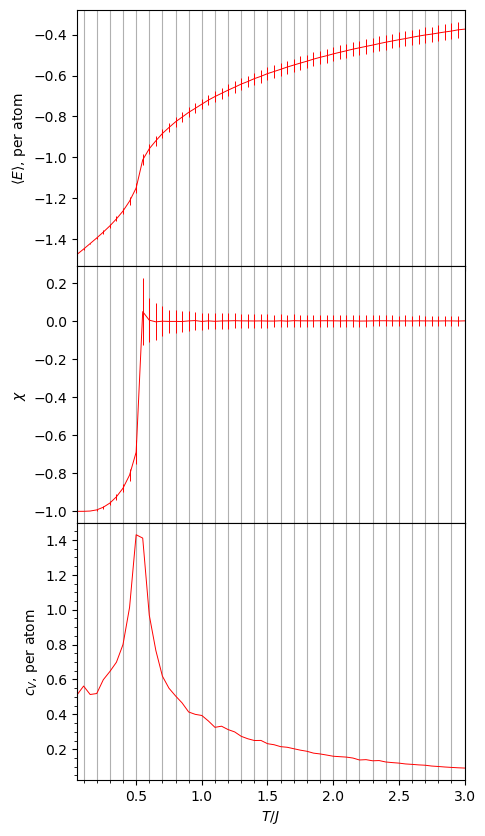

In [89]:
first_cycle = 100_000
last_cycle = 200_000

E_avg = [mean(E[first_cycle:last_cycle, n]) for n in 1:length(T_range)]
E_var = [std(E[first_cycle:last_cycle, n]) for n in 1:length(T_range)]

χ_avg = [mean(χ[first_cycle:last_cycle, n]) for n in 1:length(T_range)]
χ_var = [std(χ[first_cycle:last_cycle, n]) for n in 1:length(T_range)]

E2_avg = [mean(E[first_cycle:last_cycle, n] .^ 2) for n in 1:length(T_range)]
cV = (E2_avg - (E_avg .^ 2)) ./ (collect(T_range) .^ 2)

plt.figure(figsize=(5,10))
gs = plt.matplotlib.gridspec.GridSpec(3, 1, hspace=0)

ax1 = plt.subplot(gs[1])
ax1.errorbar(collect(T_range), E_avg / (L1 * L2), yerr=E_var / (L1 * L2), lw=0.7, color="red")
ax1.set_ylabel(raw"$\langle E\rangle$, per atom")
plt.setp(ax1.get_xticklabels(), visible=false)
ax1.grid(axis="x", which="both")

ax2 = plt.subplot(gs[2], sharex=ax1)
ax2.errorbar(collect(T_range), χ_avg, yerr=χ_var, lw=0.7, color="red")
ax2.set_ylabel(raw"$\chi$")
plt.setp(ax2.get_xticklabels(), visible=false)
ax2.grid(axis="x", which="both")

ax3 = plt.subplot(gs[3], sharex=ax1)
ax3.plot(collect(T_range), cV / (L1 * L2), lw=0.7, color="red")
ax3.set_ylabel(raw"$c_V$, per atom")
ax3.grid(axis="x", which="both")

ax3.set_xlim((first(T_range), last(T_range)))
ax3.set_xlabel(raw"$T/J$")
ax3.minorticks_on()
plt.show()